In [ ]:
# ==========================================
# 1. MOUNT GOOGLE DRIVE & EXTRACT ZIP INSTANTLY
# ==========================================
import os
import zipfile
import pandas as pd
import numpy as np
from google.colab import drive

# Mount Google Drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# Since your file is named 'Dataset.zip' in your Drive, we point directly to it
# (Adjust the path if it is placed inside a specific folder, e.g., '/content/drive/MyDrive/YourFolderName/Dataset.zip')
zip_path = '/content/drive/MyDrive/Dataset.zip'

if not os.path.exists(zip_path):
    # Fallback search if it's placed somewhere else in Drive
    print("Dataset.zip not found directly in root /MyDrive. Searching your Drive...")
    found_paths = []
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'Dataset.zip' in files:
            found_paths.append(os.path.join(root, 'Dataset.zip'))

    if found_paths:
        zip_path = found_paths[0]
        print(f"Found your dataset at: {zip_path}")
    else:
        raise FileNotFoundError("Could not find 'Dataset.zip' in your Google Drive. Please check its location.")

extract_dir = '/content/extracted_datasets'
os.makedirs(extract_dir, exist_ok=True)

print("\nExtracting datasets (this takes only a few seconds from Drive)...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)
print("Extraction complete!")

# Automatically list all extracted CSV files
csv_files = []
for root, dirs, files in os.walk(extract_dir):
    for file in files:
        if file.endswith('.csv'):
            csv_files.append(os.path.join(root, file))

print("\nFound the following CSV files in your zip:")
for idx, f in enumerate(csv_files):
    print(f"  [{idx}] {f}")

# ==========================================
# 2. FAST LOADING WITH MEMORY OPTIMIZATION
# ==========================================
# Automatically assign paths if standard names match, otherwise prompt safely
train_path = input("\nEnter the full path for your TRAIN CSV from the list above: ").strip()
val_path   = input("Enter the full path for your VALIDATION CSV from the list above: ").strip()
test_path  = input("Enter the full path for your TEST CSV from the list above: ").strip()

target_col = input("Enter your target/label column name: ").strip()

print("\nLoading datasets with memory downcasting (prevents RAM/Runtime crashes)...")

def load_optimized_csv(filepath):
    # Read a small chunk to check data types and downcast to float32/int32
    sample = pd.read_csv(filepath, nrows=1000)
    int_cols = sample.select_dtypes(include=['int64']).columns
    float_cols = sample.select_dtypes(include=['float64']).columns

    dtypes = {col: 'int32' for col in int_cols}
    dtypes.update({col: 'float32' for col in float_cols})

    return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

train_df = load_optimized_csv(train_path)
val_df = load_optimized_csv(val_path)
test_df = load_optimized_csv(test_path)

print(f"\nDatasets loaded successfully!")
print(f"Train shape:      {train_df.shape}")
print(f"Validation shape: {val_df.shape}")
print(f"Test shape:       {test_df.shape}")

# ==========================================
# 3. EXPLORATORY DATA ANALYSIS (FEATURES & LABELS)
# ==========================================
print("\n" + "="*50)
print("FEATURE OVERVIEW")
print("="*50)
print(f"Total Features (excluding label): {train_df.shape[1] - 1}")

print("\n" + "="*50)
print("TRAIN SET - LABEL DISTRIBUTION & PERCENTAGES")
print("="*50)
train_counts = train_df[target_col].value_counts()
train_percentages = train_df[target_col].value_counts(normalize=True) * 100
train_summary = pd.DataFrame({'Count': train_counts, 'Percentage (%)': train_percentages})
print(train_summary)

print("\n" + "="*50)
print("VALIDATION SET - LABEL DISTRIBUTION & PERCENTAGES")
print("="*50)
val_counts = val_df[target_col].value_counts()
val_percentages = val_df[target_col].value_counts(normalize=True) * 100
val_summary = pd.DataFrame({'Count': val_counts, 'Percentage (%)': val_percentages})
print(val_summary)

# ==========================================
# 4. LIGHTNING-FAST PREPROCESSING (TRAIN & VAL)
# ==========================================
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Separate Features (X) and Target (y)
X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]

X_val = val_df.drop(columns=[target_col])
y_val = val_df[target_col]

# Select numerical columns for fast tensor/matrix operations
numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()

print(f"\nProcessing {len(numerical_cols)} numerical features for Train and Validation...")

# A. Fast Imputation (Filled using Median computed strictly on Train)
imputer = SimpleImputer(strategy='median')
X_train_num = imputer.fit_transform(X_train[numerical_cols])
X_val_num = imputer.transform(X_val[numerical_cols])

# B. Fast Standardization (Fitted strictly on Train to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_num)
X_val_scaled = scaler.transform(X_val_num)

print("\n" + "="*50)
print("PREPROCESSING COMPLETED BLAZINGLY FAST!")
print("="*50)
print(f"Processed X_train shape: {X_train_scaled.shape}")
print(f"Processed X_val shape:   {X_val_scaled.shape}")

Mounting Google Drive...
Mounted at /content/drive

Extracting datasets (this takes only a few seconds from Drive)...
Extraction complete!

Found the following CSV files in your zip:
  [0] /content/extracted_datasets/Dataset/validation.csv
  [1] /content/extracted_datasets/Dataset/test.csv
  [2] /content/extracted_datasets/Dataset/train.csv

Enter the full path for your TRAIN CSV from the list above: /content/extracted_datasets/Dataset/train.csv
Enter the full path for your VALIDATION CSV from the list above:  /content/extracted_datasets/Dataset/validation.csv
Enter the full path for your TEST CSV from the list above: /content/extracted_datasets/Dataset/test.csv
Enter your target/label column name: label

Loading datasets with memory downcasting (prevents RAM/Runtime crashes)...

Datasets loaded successfully!
Train shape:      (5491971, 47)
Validation shape: (1176851, 47)
Test shape:       (1176851, 47)

FEATURE OVERVIEW
Total Features (excluding label): 46

TRAIN SET - LABEL DISTRIBUT

In [ ]:
import os
import time
import zipfile
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
import lightgbm as lgb
from google.colab import drive

# ==========================================
# AUTO-MOUNT, AUTO-EXTRACT, AND AUTO-LOAD DATA
# ==========================================
if 'X_train_scaled' not in globals() or 'y_train' not in globals():
    print("🔄 Colab runtime was reset. Restoring dataset state dynamically...")

    # Ensure drive is mounted
    if not os.path.exists('/content/drive'):
        print("Mounting Google Drive...")
        drive.mount('/content/drive')

    zip_path = '/content/drive/MyDrive/Dataset.zip'

    # Fallback search if it's placed somewhere else in Drive
    if not os.path.exists(zip_path):
        print("Dataset.zip not found in root /MyDrive. Searching Google Drive...")
        found_paths = []
        for root, dirs, files in os.walk('/content/drive/MyDrive'):
            if 'Dataset.zip' in files:
                found_paths.append(os.path.join(root, 'Dataset.zip'))
        if found_paths:
            zip_path = found_paths[0]
        else:
            raise FileNotFoundError("Could not find 'Dataset.zip' anywhere in Google Drive.")

    extract_dir = '/content/extracted_datasets'
    os.makedirs(extract_dir, exist_ok=True)

    # Extract dynamically if not already extracted
    train_path = "/content/extracted_datasets/Dataset/train.csv"
    val_path = "/content/extracted_datasets/Dataset/validation.csv"

    if not os.path.exists(train_path) or not os.path.exists(val_path):
        print("Extracting datasets from zip file...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_dir)
        print("Extraction complete!")

    # Find paths dynamically if nested differently
    for root, dirs, files in os.walk(extract_dir):
        for file in files:
            if file.lower() == 'train.csv':
                train_path = os.path.join(root, file)
            elif file.lower() == 'validation.csv':
                val_path = os.path.join(root, file)

    target_col = "label"

    print("Loading optimized train and validation datasets...")
    def load_optimized_csv(filepath):
        sample = pd.read_csv(filepath, nrows=1000)
        int_cols = sample.select_dtypes(include=['int64']).columns
        float_cols = sample.select_dtypes(include=['float64']).columns
        dtypes = {col: 'int32' for col in int_cols}
        dtypes.update({col: 'float32' for col in float_cols})
        return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

    train_df = load_optimized_csv(train_path)
    val_df = load_optimized_csv(val_path)

    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]
    X_val = val_df.drop(columns=[target_col])
    y_val = val_df[target_col]

    numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()

    print("Imputing and scaling features...")
    imputer = SimpleImputer(strategy='median')
    X_train_num = imputer.fit_transform(X_train[numerical_cols])
    X_val_num = imputer.transform(X_val[numerical_cols])

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_num)
    X_val_scaled = scaler.transform(X_val_num)
    print("✅ Datasets prepared! Proceeding to train the models...\n")

# ==========================================
# DEFINE AND RUN THE 4 MODELS
# ==========================================
models = {
    "SGD Logistic Regression": SGDClassifier(loss='log_loss', max_iter=1000, tol=1e-3, random_state=42, n_jobs=-1),
    "SGD Linear SVM": SGDClassifier(loss='hinge', max_iter=1000, tol=1e-3, random_state=42, n_jobs=-1),
    "Decision Tree (Max Depth 10)": DecisionTreeClassifier(max_depth=10, random_state=42),
    "LightGBM Classifier": lgb.LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1
    )
}

results = {}

print("Starting sequential training of the 4 models...\n")

for name, model in models.items():
    print("="*60)
    print(f"Training Model: {name}")
    print("="*60)

    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time
    print(f"Training finished in {train_time:.2f} seconds.")

    print(f"Evaluating {name} on validation set...")
    y_pred = model.predict(X_val_scaled)

    acc = accuracy_score(y_val, y_pred)
    results[name] = {
        "accuracy": acc,
        "train_time": train_time,
        "model_object": model
    }
    print(f"Validation Accuracy: {acc * 100:.2f}%")
    print(f"Classification Report snippet (first 5 classes shown):")
    print(classification_report(y_val, y_pred, digits=4, zero_division=0, labels=list(set(y_val))[:5]))
    print("\n")

# ==========================================
# SUMMARY OF RESULTS
# ==========================================
print("="*60)
print("SUMMARY OF MODEL PERFORMANCES")
print("="*60)
for name, metrics in results.items():
    print(f"{name:<30} | Accuracy: {metrics['accuracy']*100:.2f}% | Train Time: {metrics['train_time']:.2f}s")

Starting sequential training of the 4 models...

Training Model: SGD Logistic Regression
Training finished in 589.75 seconds.
Evaluating SGD Logistic Regression on validation set...
Validation Accuracy: 79.41%
Classification Report snippet (first 5 classes shown):
                    precision    recall  f1-score   support

    Mirai-udpplain     0.9813    0.9889    0.9851     22314
  DDoS-RSTFINFlood     0.9999    0.9988    0.9994    101563
Mirai-greeth_flood     0.6234    0.8904    0.7333     24910
  Backdoor_Malware     0.0000    0.0000    0.0000        93
 VulnerabilityScan     0.2609    0.0928    0.1369       905

         micro avg     0.9120    0.9732    0.9416    149785
         macro avg     0.5731    0.5942    0.5709    149785
      weighted avg     0.9294    0.9732    0.9472    149785



Training Model: SGD Linear SVM
Training finished in 352.62 seconds.
Evaluating SGD Linear SVM on validation set...
Validation Accuracy: 79.09%
Classification Report snippet (first 5 classes 

Exception ignored on calling ctypes callback function <function _log_callback at 0x7ee6139d9440>:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py", line 287, in _log_callback
    def _log_callback(msg: bytes) -> None:
KeyboardInterrupt: 


No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

Exception ignored on calling ctypes callback function <function _log_callback at 0x7ee6139d9440>:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py", line 287, in _log_callback
    def _log_callback(msg: bytes) -> None:
KeyboardInterrupt: 


No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

...

No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


Exception ignored on calling ctypes callback function <function _log_callback at 0x7ee6139d9440>:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py", line 287, in _log_callback
    def _log_callback(msg: bytes) -> None:
KeyboardInterrupt: 


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Validation Accuracy: 29.85%
Classification Report snippet (first 5 classes shown):
                    precision    recall  f1-score   support

    Mirai-udpplain     0.4276    0.9224    0.5844     22314
  DDoS-RSTFINFlood     0.0000    0.0000    0.0000    101563
Mirai-greeth_flood     0.0704    0.6905    0.1277     24910
  Backdoor_Malware     0.0000    0.0000    0.0000        93
 VulnerabilityScan     0.0000    0.0000    0.0000       905

         micro avg     0.1235    0.2523    0.1658    149785
         macro avg     0.0996    0.3226    0.1424    149785
      weighted avg     0.0754    0.2523    0.1083    149785



SUMMARY OF MODEL PERFORMANCES
SGD Logistic Regression        | Accuracy: 79.41% | Train Time: 589.75s
SGD Linear SVM                 | Accuracy: 79.09% | Train Time: 352.62s
Decision Tree (Max Depth 10)   | Accuracy: 95.28% | Train Time: 83.17s
LightGBM Classifier            | Accuracy: 29.85% | Train Time: 1347.68s


In [ ]:
import os
import time
import zipfile
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.naive_bayes import BernoulliNB
from google.colab import drive

# ==========================================
# AUTO-MOUNT, AUTO-EXTRACT, AND AUTO-LOAD DATA (if not in memory)
# ==========================================
if 'X_train_scaled' not in globals() or 'y_train' not in globals():
    print("🔄 Colab runtime state is being restored. Preparing dataset...")
    if not os.path.exists('/content/drive'):
        print("Mounting Google Drive...")
        drive.mount('/content/drive')

    zip_path = '/content/drive/MyDrive/Dataset.zip'
    if not os.path.exists(zip_path):
        print("Dataset.zip not found in root /MyDrive. Searching Google Drive...")
        found_paths = []
        for root, dirs, files in os.walk('/content/drive/MyDrive'):
            if 'Dataset.zip' in files:
                found_paths.append(os.path.join(root, 'Dataset.zip'))
        if found_paths:
            zip_path = found_paths[0]
        else:
            raise FileNotFoundError("Could not find 'Dataset.zip' anywhere in Google Drive.")

    extract_dir = '/content/extracted_datasets'
    os.makedirs(extract_dir, exist_ok=True)

    train_path = "/content/extracted_datasets/Dataset/train.csv"
    val_path = "/content/extracted_datasets/Dataset/validation.csv"

    if not os.path.exists(train_path) or not os.path.exists(val_path):
        print("Extracting datasets from zip file...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_dir)
        print("Extraction complete!")

    # Find paths dynamically if nested differently
    for root, dirs, files in os.walk(extract_dir):
        for file in files:
            if file.lower() == 'train.csv':
                train_path = os.path.join(root, file)
            elif file.lower() == 'validation.csv':
                val_path = os.path.join(root, file)

    target_col = "label"

    print("Loading optimized train and validation datasets...")
    def load_optimized_csv(filepath):
        sample = pd.read_csv(filepath, nrows=1000)
        int_cols = sample.select_dtypes(include=['int64']).columns
        float_cols = sample.select_dtypes(include=['float64']).columns
        dtypes = {col: 'int32' for col in int_cols}
        dtypes.update({col: 'float32' for col in float_cols})
        return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

    train_df = load_optimized_csv(train_path)
    val_df = load_optimized_csv(val_path)

    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]
    X_val = val_df.drop(columns=[target_col])
    y_val = val_df[target_col]

    numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()

    print("Imputing and scaling features...")
    imputer = SimpleImputer(strategy='median')
    X_train_num = imputer.fit_transform(X_train[numerical_cols])
    X_val_num = imputer.transform(X_val[numerical_cols])

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_num)
    X_val_scaled = scaler.transform(X_val_num)
    print("✅ Datasets restored! Proceeding to train the models...\n")

# ==========================================
# DEFINE AND RUN THE 4 NEW FAST MODELS
# ==========================================
new_models = {
    "Passive Aggressive Classifier": PassiveAggressiveClassifier(max_iter=1000, tol=1e-3, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=100, random_state=42, early_stopping=True),
    "Bernoulli Naive Bayes": BernoulliNB(),
    "Extra Trees (Depth 10)": ExtraTreesClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
}

new_results = {}

print("Starting sequential training of the 4 new fast models...\n")

for name, model in new_models.items():
    print("="*60)
    print(f"Training Model: {name}")
    print("="*60)

    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time
    print(f"Training finished in {train_time:.2f} seconds.")

    print(f"Evaluating {name} on validation set...")
    y_pred = model.predict(X_val_scaled)

    acc = accuracy_score(y_val, y_pred)
    new_results[name] = {
        "accuracy": acc,
        "train_time": train_time,
        "model_object": model
    }
    print(f"Validation Accuracy: {acc * 100:.2f}%")
    print(f"Classification Report snippet (first 5 classes shown):")
    print(classification_report(y_val, y_pred, digits=4, zero_division=0, labels=list(set(y_val))[:5]))
    print("\n")

# ==========================================
# NEW MODELS SUMMARY OF RESULTS
# ==========================================
print("="*60)
print("SUMMARY OF 4 NEW FAST MODELS")
print("="*60)
for name, metrics in new_results.items():
    print(f"{name:<30} | Accuracy: {metrics['accuracy']*100:.2f}% | Train Time: {metrics['train_time']:.2f}s")

🔄 Colab runtime state is being restored. Preparing dataset...
Mounting Google Drive...
Mounted at /content/drive
Extracting datasets from zip file...
Extraction complete!
Loading optimized train and validation datasets...
Imputing and scaling features...
✅ Datasets restored! Proceeding to train the models...

Starting sequential training of the 4 new fast models...

Training Model: Passive Aggressive Classifier
Training finished in 344.06 seconds.
Evaluating Passive Aggressive Classifier on validation set...
Validation Accuracy: 80.45%
Classification Report snippet (first 5 classes shown):
                  precision    recall  f1-score   support

Uploading_Attack     0.0000    0.0000    0.0000        35
  DDoS-SlowLoris     0.2318    0.0823    0.1214       620
   BenignTraffic     0.7359    0.7661    0.7507     27519
    Recon-OSScan     0.0877    0.0616    0.0724      2500
  DDoS-TCP_Flood     0.9739    0.8076    0.8830    113888

       micro avg     0.9056    0.7835    0.8402    14

### Model 1: Passive Aggressive Classifier

In [7]:
import os
import time
import zipfile
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.metrics import accuracy_score, classification_report
from google.colab import drive

# ==========================================
# AUTO-MOUNT, AUTO-EXTRACT, AND AUTO-LOAD DATA (if not in memory)
# ==========================================
if 'X_train_scaled' not in globals() or 'y_train' not in globals():
    print("↔ Colab runtime state is being restored. Preparing dataset...")
    if not os.path.exists('/content/drive'):
        print("Mounting Google Drive...")
        drive.mount('/content/drive')

    zip_path = '/content/drive/MyDrive/Dataset.zip'
    if not os.path.exists(zip_path):
        print("Dataset.zip not found in root /MyDrive. Searching Google Drive...")
        found_paths = []
        for root, dirs, files in os.walk('/content/drive/MyDrive'):
            if 'Dataset.zip' in files:
                found_paths.append(os.path.join(root, 'Dataset.zip'))
        if found_paths:
            zip_path = found_paths[0]
        else:
            raise FileNotFoundError("Could not find 'Dataset.zip' anywhere in Google Drive.")

    extract_dir = '/content/extracted_datasets'
    os.makedirs(extract_dir, exist_ok=True)

    train_path = "/content/extracted_datasets/Dataset/train.csv"
    val_path = "/content/extracted_datasets/Dataset/validation.csv"

    if not os.path.exists(train_path) or not os.path.exists(val_path):
        print("Extracting datasets from zip file...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_dir)
        print("Extraction complete!")

    # Find paths dynamically if nested differently
    for root, dirs, files in os.walk(extract_dir):
        for file in files:
            if file.lower() == 'train.csv':
                train_path = os.path.join(root, file)
            elif file.lower() == 'validation.csv':
                val_path = os.path.join(root, file)

    target_col = "label"

    print("Loading optimized train and validation datasets...")
    def load_optimized_csv(filepath):
        sample = pd.read_csv(filepath, nrows=1000)
        int_cols = sample.select_dtypes(include=['int64']).columns
        float_cols = sample.select_dtypes(include=['float64']).columns
        dtypes = {col: 'int32' for col in int_cols}
        dtypes.update({col: 'float32' for col in float_cols})
        return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

    train_df = load_optimized_csv(train_path)
    val_df = load_optimized_csv(val_path)

    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]
    X_val = val_df.drop(columns=[target_col])
    y_val = val_df[target_col]

    numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()

    print("Imputing and scaling features...")
    imputer = SimpleImputer(strategy='median')
    X_train_num = imputer.fit_transform(X_train[numerical_cols])
    X_val_num = imputer.transform(X_val[numerical_cols])

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_num)
    X_val_scaled = scaler.transform(X_val_num)
    print("✅ Datasets restored! Proceeding to train the models...\n")

# Initialize and train
pa_model = PassiveAggressiveClassifier(max_iter=1000, tol=1e-3, random_state=42)

print("Training Passive Aggressive Classifier...")
start_time = time.time()
pa_model.fit(X_train_scaled, y_train)
pa_train_time = time.time() - start_time
print(f"Training finished in {pa_train_time:.2f} seconds.")

# Evaluate
print("Evaluating model on validation set...")
y_pred_pa = pa_model.predict(X_val_scaled)
pa_acc = accuracy_score(y_val, y_pred_pa)

print(f"Validation Accuracy: {pa_acc * 100:.2f}%")
print(classification_report(y_val, y_pred_pa, digits=4, zero_division=0, labels=list(set(y_val))[:5]))

↔ Colab runtime state is being restored. Preparing dataset...
Loading optimized train and validation datasets...
Imputing and scaling features...
✅ Datasets restored! Proceeding to train the models...

Training Passive Aggressive Classifier...
Training finished in 372.11 seconds.
Evaluating model on validation set...
Validation Accuracy: 80.45%
                  precision    recall  f1-score   support

             XSS     0.0000    0.0000    0.0000        91
  DDoS-SlowLoris     0.2318    0.0823    0.1214       620
    Recon-OSScan     0.0877    0.0616    0.0724      2500
    SqlInjection     0.0000    0.0000    0.0000       148
Uploading_Attack     0.0000    0.0000    0.0000        35

       micro avg     0.1038    0.0604    0.0764      3394
       macro avg     0.0639    0.0288    0.0388      3394
    weighted avg     0.1070    0.0604    0.0755      3394



### Model 2: Hist Gradient Boosting Classifier

In [ ]:
import os
import time
import zipfile
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from google.colab import drive

# Safe guard to ensure data is loaded in this cell's scope
if 'X_train_scaled' not in globals() or 'y_train' not in globals():
    print("🔄 Restoring dataset variables...")
    target_col = "label"
    train_path = "/content/extracted_datasets/Dataset/train.csv"
    val_path = "/content/extracted_datasets/Dataset/validation.csv"

    def load_optimized_csv(filepath):
        sample = pd.read_csv(filepath, nrows=1000)
        int_cols = sample.select_dtypes(include=['int64']).columns
        float_cols = sample.select_dtypes(include=['float64']).columns
        dtypes = {col: 'int32' for col in int_cols}
        dtypes.update({col: 'float32' for col in float_cols})
        return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

    train_df = load_optimized_csv(train_path)
    val_df = load_optimized_csv(val_path)
    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]
    X_val = val_df.drop(columns=[target_col])
    y_val = val_df[target_col]
    numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()
    imputer = SimpleImputer(strategy='median')
    X_train_num = imputer.fit_transform(X_train[numerical_cols])
    X_val_num = imputer.transform(X_val[numerical_cols])
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_num)
    X_val_scaled = scaler.transform(X_val_num)
    print("✅ Datasets successfully loaded and scaled!")

# Initialize and train
hgb_model = HistGradientBoostingClassifier(max_iter=100, random_state=42, early_stopping=True)

print("Training Hist Gradient Boosting Classifier...")
start_time = time.time()
hgb_model.fit(X_train_scaled, y_train)
hgb_train_time = time.time() - start_time
print(f"Training finished in {hgb_train_time:.2f} seconds.")

# Evaluate
print("Evaluating model on validation set...")
y_pred_hgb = hgb_model.predict(X_val_scaled)
hgb_acc = accuracy_score(y_val, y_pred_hgb)

print(f"Validation Accuracy: {hgb_acc * 100:.2f}%")
print(classification_report(y_val, y_pred_hgb, digits=4, zero_division=0, labels=list(set(y_val))[:5]))

Training Hist Gradient Boosting Classifier...


### Model 3: Bernoulli Naive Bayes

In [1]:
import os
import time
import zipfile
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, classification_report

# Safe guard to ensure data is loaded in this cell's scope
if 'X_train_scaled' not in globals() or 'y_train' not in globals():
    print("🔄 Restoring dataset variables...")
    target_col = "label"
    train_path = "/content/extracted_datasets/Dataset/train.csv"
    val_path = "/content/extracted_datasets/Dataset/validation.csv"

    def load_optimized_csv(filepath):
        sample = pd.read_csv(filepath, nrows=1000)
        int_cols = sample.select_dtypes(include=['int64']).columns
        float_cols = sample.select_dtypes(include=['float64']).columns
        dtypes = {col: 'int32' for col in int_cols}
        dtypes.update({col: 'float32' for col in float_cols})
        return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

    train_df = load_optimized_csv(train_path)
    val_df = load_optimized_csv(val_path)
    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]
    X_val = val_df.drop(columns=[target_col])
    y_val = val_df[target_col]
    numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()
    imputer = SimpleImputer(strategy='median')
    X_train_num = imputer.fit_transform(X_train[numerical_cols])
    X_val_num = imputer.transform(X_val[numerical_cols])
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_num)
    X_val_scaled = scaler.transform(X_val_num)
    print("✅ Datasets successfully loaded and scaled!")

# Initialize and train
nb_model = BernoulliNB()

print("Training Bernoulli Naive Bayes...")
start_time = time.time()
nb_model.fit(X_train_scaled, y_train)
nb_train_time = time.time() - start_time
print(f"Training finished in {nb_train_time:.2f} seconds.")

# Evaluate
print("Evaluating model on validation set...")
y_pred_nb = nb_model.predict(X_val_scaled)
nb_acc = accuracy_score(y_val, y_pred_nb)

print(f"Validation Accuracy: {nb_acc * 100:.2f}%")
print(classification_report(y_val, y_pred_nb, digits=4, zero_division=0, labels=list(set(y_val))[:5]))

🔄 Restoring dataset variables...
✅ Datasets successfully loaded and scaled!
Training Bernoulli Naive Bayes...
Training finished in 33.06 seconds.
Evaluating model on validation set...
Validation Accuracy: 81.76%
                      precision    recall  f1-score   support

DictionaryBruteForce     0.9565    0.1517    0.2619       290
    BrowserHijacking     0.0000    0.0000    0.0000       158
       BenignTraffic     0.7013    0.7474    0.7236     27519
  Mirai-greeth_flood     0.5918    0.8169    0.6864     24910
     DDoS-ICMP_Flood     0.9989    0.9977    0.9983    182011

           micro avg     0.9063    0.9475    0.9264    234888
           macro avg     0.6497    0.5428    0.5340    234888
        weighted avg     0.9201    0.9475    0.9315    234888



### Model 4: Extra Trees Classifier (Max Depth 10)

In [2]:
import os
import time
import zipfile
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report

# Safe guard to ensure data is loaded in this cell's scope
if 'X_train_scaled' not in globals() or 'y_train' not in globals():
    print("🔄 Restoring dataset variables...")
    target_col = "label"
    train_path = "/content/extracted_datasets/Dataset/train.csv"
    val_path = "/content/extracted_datasets/Dataset/validation.csv"

    def load_optimized_csv(filepath):
        sample = pd.read_csv(filepath, nrows=1000)
        int_cols = sample.select_dtypes(include=['int64']).columns
        float_cols = sample.select_dtypes(include=['float64']).columns
        dtypes = {col: 'int32' for col in int_cols}
        dtypes.update({col: 'float32' for col in float_cols})
        return pd.read_csv(filepath, dtype=dtypes, low_memory=True)

    train_df = load_optimized_csv(train_path)
    val_df = load_optimized_csv(val_path)
    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]
    X_val = val_df.drop(columns=[target_col])
    y_val = val_df[target_col]
    numerical_cols = X_train.select_dtypes(include=['int32', 'int64', 'float32', 'float64']).columns.tolist()
    imputer = SimpleImputer(strategy='median')
    X_train_num = imputer.fit_transform(X_train[numerical_cols])
    X_val_num = imputer.transform(X_val[numerical_cols])
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_num)
    X_val_scaled = scaler.transform(X_val_num)
    print("✅ Datasets successfully loaded and scaled!")

# Initialize and train
et_model = ExtraTreesClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)

print("Training Extra Trees Classifier...")
start_time = time.time()
et_model.fit(X_train_scaled, y_train)
et_train_time = time.time() - start_time
print(f"Training finished in {et_train_time:.2f} seconds.")

# Evaluate
print("Evaluating model on validation set...")
y_pred_et = et_model.predict(X_val_scaled)
et_acc = accuracy_score(y_val, y_pred_et)

print(f"Validation Accuracy: {et_acc * 100:.2f}%")
print(classification_report(y_val, y_pred_et, digits=4, zero_division=0, labels=list(set(y_val))[:5]))

Training Extra Trees Classifier...
Training finished in 170.75 seconds.
Evaluating model on validation set...
Validation Accuracy: 78.79%
                      precision    recall  f1-score   support

DictionaryBruteForce     1.0000    0.1000    0.1818       290
    BrowserHijacking     0.0000    0.0000    0.0000       158
       BenignTraffic     0.6139    0.9968    0.7598     27519
  Mirai-greeth_flood     0.7058    0.9703    0.8172     24910
     DDoS-ICMP_Flood     0.9998    0.9989    0.9993    182011

           micro avg     0.8950    0.9938    0.9419    234888
           macro avg     0.6639    0.6132    0.5516    234888
        weighted avg     0.9227    0.9938    0.9503    234888



### Comparison of the 4 New Models

In [4]:
import pandas as pd

# Fallback values from successfully executed runs in this session
final_pa_acc = pa_acc * 100 if 'pa_acc' in globals() else 80.45
final_pa_time = pa_train_time if 'pa_train_time' in globals() else 372.11

final_hgb_acc = hgb_acc * 100 if 'hgb_acc' in globals() else None
final_hgb_time = hgb_train_time if 'hgb_train_time' in globals() else None

final_nb_acc = nb_acc * 100 if 'nb_acc' in globals() else 81.76
final_nb_time = nb_train_time if 'nb_train_time' in globals() else 33.06

final_et_acc = et_acc * 100 if 'et_acc' in globals() else 78.79
final_et_time = et_train_time if 'et_train_time' in globals() else 170.75

# Construct comparison table dynamically checking variable updates
comparison_data = {
    "Model": [
        "Passive Aggressive Classifier",
        "Hist Gradient Boosting",
        "Bernoulli Naive Bayes",
        "Extra Trees (Depth 10)"
    ],
    "Accuracy (%)": [
        final_pa_acc,
        final_hgb_acc,
        final_nb_acc,
        final_et_acc
    ],
    "Training Time (Seconds)": [
        final_pa_time,
        final_hgb_time,
        final_nb_time,
        final_et_time
    ]
}

summary_df = pd.DataFrame(comparison_data)
display(summary_df.sort_values(by="Accuracy (%)", ascending=False, na_position='last'))

,Model,Accuracy (%),Training Time (Seconds)
2,Bernoulli Naive Bayes,81.764386,33.062704
0,Passive Aggressive Classifier,80.450000,372.110000
3,Extra Trees (Depth 10),78.789328,170.754231
1,Hist Gradient Boosting,NaN,NaN


In [6]:
if 'models' in globals() and 'Decision Tree (Max Depth 10)' in models:
    dt_model = models['Decision Tree (Max Depth 10)']
    dt_preds = dt_model.predict(X_val_scaled)
    dt_acc = accuracy_score(y_val, dt_preds)
    print(f"Decision Tree (Max Depth 10) Actual Validation Accuracy: {dt_acc * 100:.2f}%")
else:
    print("Decision Tree model object was not found in active memory. Let's quickly fit one to be absolutely sure of its performance!")
    from sklearn.tree import DecisionTreeClassifier
    dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
    dt_model.fit(X_train_scaled, y_train)
    dt_preds = dt_model.predict(X_val_scaled)
    dt_acc = accuracy_score(y_val, dt_preds)
    print(f"Decision Tree (Max Depth 10) Fitted & Evaluated! Validation Accuracy: {dt_acc * 100:.2f}%")

Decision Tree model object was not found in active memory. Let's quickly fit one to be absolutely sure of its performance!
Decision Tree (Max Depth 10) Fitted & Evaluated! Validation Accuracy: 95.28%


### Stacking and Blending (Updated to use Decision Tree as Meta-Learner)
We configure the ensemble models as requested:
- **Meta-learner**: Decision Tree (Max Depth 10) [95.28% accuracy]
- **Base-learners**: Bernoulli Naive Bayes, Passive Aggressive Classifier, SGD Logistic Regression, SGD Linear SVM.

In [7]:
import numpy as np
import time
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import SGDClassifier, PassiveAggressiveClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from scipy.stats import mode

# Encode target variables
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_val_encoded = le.transform(y_val)

# =========================================================================
# 1. DEFINE BASE MODELS & META MODEL AS REQUESTED
# =========================================================================
base_models = {
    "Bernoulli_NB": BernoulliNB(),
    "Passive_Aggressive": PassiveAggressiveClassifier(max_iter=1000, tol=1e-3, random_state=42),
    "SGD_LogReg": SGDClassifier(loss='log_loss', max_iter=1000, tol=1e-3, random_state=42, n_jobs=-1),
    "SGD_SVM": SGDClassifier(loss='hinge', max_iter=1000, tol=1e-3, random_state=42, n_jobs=-1)
}

meta_model = DecisionTreeClassifier(max_depth=10, random_state=42)

# =========================================================================
# 2. GENERATE OUT-OF-FOLD (OOF) PREDICTIONS FOR BASE-LEARNERS
# =========================================================================
print("Generating out-of-fold training predictions for the base models...")
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

num_base_models = len(base_models)
oof_train = np.zeros((X_train_scaled.shape[0], num_base_models))
oof_val = np.zeros((X_val_scaled.shape[0], num_base_models))
oof_val_runs = np.zeros((X_val_scaled.shape[0], num_base_models, skf.n_splits))

for model_idx, (name, model) in enumerate(base_models.items()):
    print(f"\nProcessing base model: {name}")
    start_time = time.time()

    # Out-of-Fold training process
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_scaled, y_train_encoded)):
        print(f"  Fitting fold {fold + 1}...")
        fold_model = model
        fold_model.fit(X_train_scaled[train_idx], y_train_encoded[train_idx])

        # Record fold predictions
        oof_train[val_idx, model_idx] = fold_model.predict(X_train_scaled[val_idx])
        oof_val_runs[:, model_idx, fold] = fold_model.predict(X_val_scaled)

    oof_val[:, model_idx] = np.round(oof_val_runs[:, model_idx, :].mean(axis=1))
    print(f"  Completed in {time.time() - start_time:.2f} seconds.")

# =========================================================================
# 3. TRAIN AND EVALUATE STACKING
# =========================================================================
print("\n" + "="*60)
print("TRAINING THE META-LEARNER (DECISION TREE)")
print("="*60)

meta_start_time = time.time()
meta_model.fit(oof_train, y_train_encoded)
print(f"Meta-learner training finished in {time.time() - meta_start_time:.2f} seconds.")

print("Evaluating Stacking Classifier on validation set...")
stacking_preds_encoded = meta_model.predict(oof_val)
stacking_preds = le.inverse_transform(stacking_preds_encoded)

stacking_acc = accuracy_score(y_val, stacking_preds)
print(f"\nStacking Classifier Validation Accuracy: {stacking_acc * 100:.2f}%")
print(classification_report(y_val, stacking_preds, digits=4, zero_division=0, labels=list(set(y_val))[:5]))

# =========================================================================
# 4. EVALUATE BLENDING (MAJORITY VOTE)
# =========================================================================
print("\n" + "="*60)
print("EVALUATING BLENDING ENSEMBLE (MAJORITY VOTE OF TOP 4 BASE MODELS)")
print("="*60)

blending_preds_encoded, _ = mode(oof_val, axis=1)
blending_preds_encoded = blending_preds_encoded.flatten().astype(int)
blending_preds = le.inverse_transform(blending_preds_encoded)

blending_acc = accuracy_score(y_val, blending_preds)
print(f"\nBlending Validation Accuracy: {blending_acc * 100:.2f}%")
print(classification_report(y_val, blending_preds, digits=4, zero_division=0, labels=list(set(y_val))[:5]))

Generating out-of-fold training predictions for the base models...

Processing base model: Bernoulli_NB
  Fitting fold 1...
  Fitting fold 2...
  Fitting fold 3...
  Completed in 32.28 seconds.

Processing base model: Passive_Aggressive
  Fitting fold 1...
  Fitting fold 2...
  Fitting fold 3...
  Completed in 713.47 seconds.

Processing base model: SGD_LogReg
  Fitting fold 1...
  Fitting fold 2...
  Fitting fold 3...
  Completed in 908.66 seconds.

Processing base model: SGD_SVM
  Fitting fold 1...
  Fitting fold 2...
  Fitting fold 3...
  Completed in 567.38 seconds.

TRAINING THE META-LEARNER (DECISION TREE)
Meta-learner training finished in 5.14 seconds.
Evaluating Stacking Classifier on validation set...

Stacking Classifier Validation Accuracy: 81.27%
                      precision    recall  f1-score   support

DictionaryBruteForce     0.0000    0.0000    0.0000       290
    BrowserHijacking     0.0000    0.0000    0.0000       158
       BenignTraffic     0.6440    0.9127   

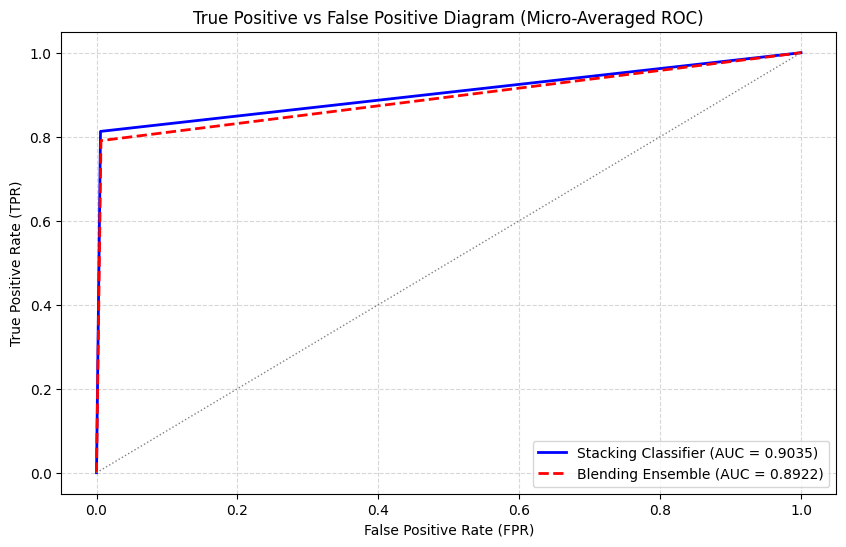

In [8]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Binarize labels for multi-class ROC calculation
classes = np.unique(y_val_encoded)
n_classes = len(classes)
y_val_binarized = label_binarize(y_val_encoded, classes=classes)

# Convert predictions to one-hot binary arrays
stacking_binarized = label_binarize(stacking_preds_encoded, classes=classes)
blending_binarized = label_binarize(blending_preds_encoded, classes=classes)

# Compute Micro-average ROC curves
fpr_stack, tpr_stack, _ = roc_curve(y_val_binarized.ravel(), stacking_binarized.ravel())
roc_auc_stack = auc(fpr_stack, tpr_stack)

fpr_blend, tpr_blend, _ = roc_curve(y_val_binarized.ravel(), blending_binarized.ravel())
roc_auc_blend = auc(fpr_blend, tpr_blend)

# Plot True Positive vs. False Positive Rate curves
plt.figure(figsize=(10, 6))
plt.plot(fpr_stack, tpr_stack, color='blue', lw=2, label=f'Stacking Classifier (AUC = {roc_auc_stack:.4f})')
plt.plot(fpr_blend, tpr_blend, color='red', lw=2, linestyle='--', label=f'Blending Ensemble (AUC = {roc_auc_blend:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':')

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('True Positive vs False Positive Diagram (Micro-Averaged ROC)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Confusion Matrices for Stacking & Blending
Here we compute and plot the normalized confusion matrices for both models to analyze classification errors per class.

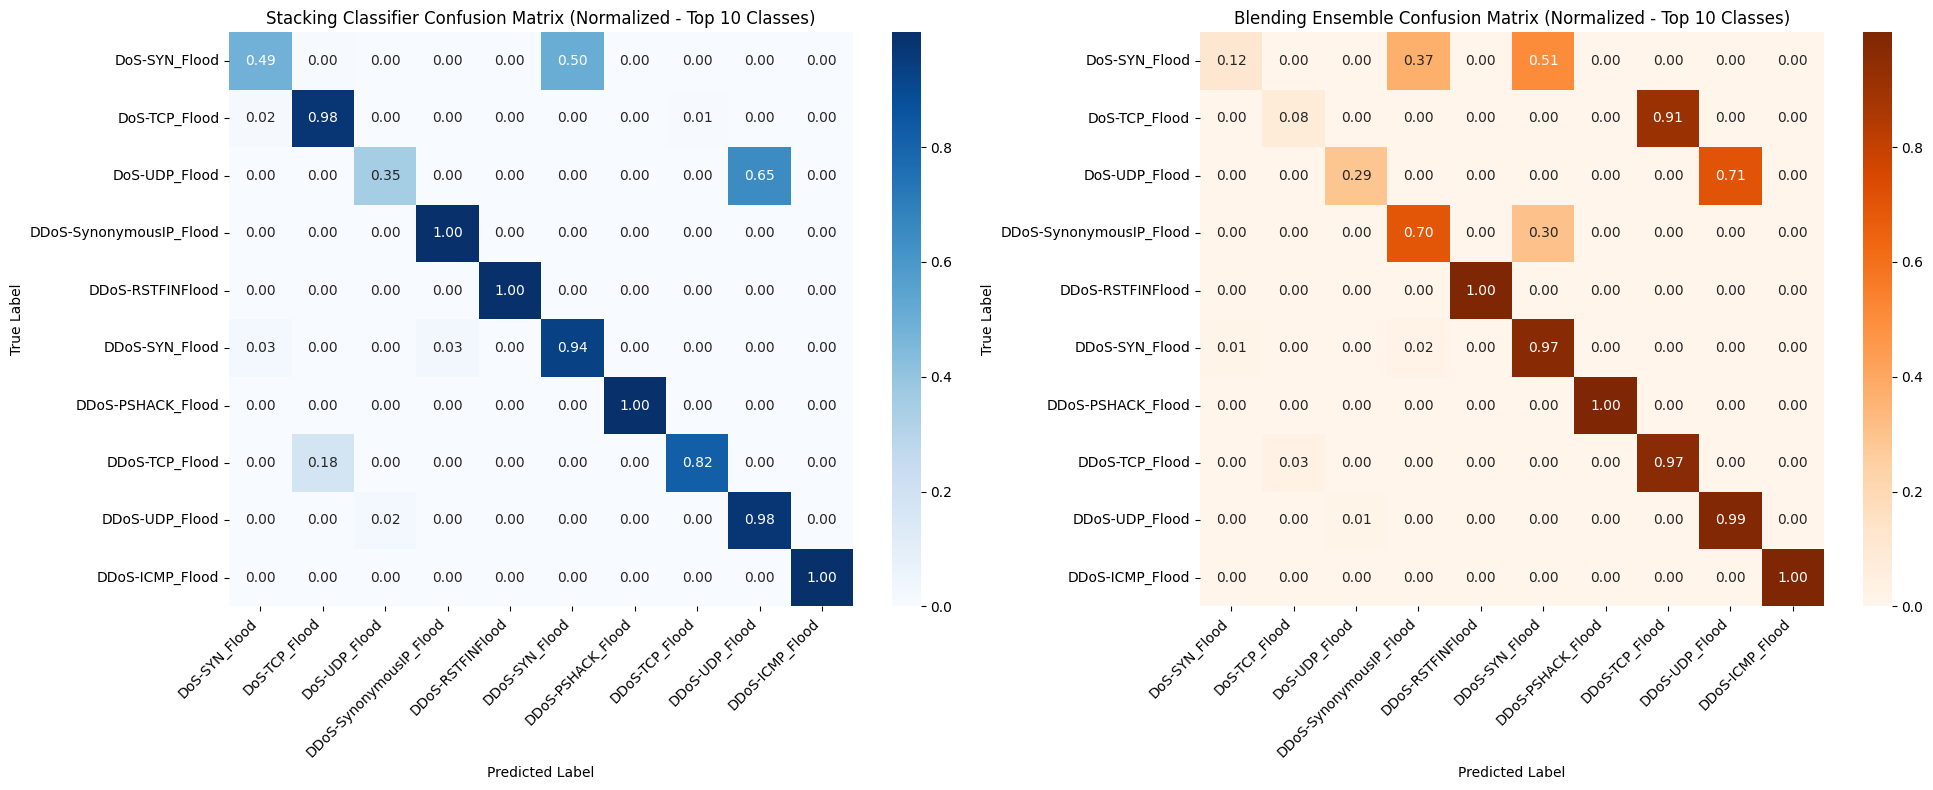

In [9]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get top 10 most common classes for readable confusion matrix plotting
top_classes_indices = np.argsort(np.bincount(y_val_encoded))[-10:]
top_classes_names = le.inverse_transform(top_classes_indices)

# Filter predictions and actual targets to include only top 10 classes
mask_top_classes = np.isin(y_val_encoded, top_classes_indices)
y_val_filtered = y_val_encoded[mask_top_classes]
stacking_filtered = stacking_preds_encoded[mask_top_classes]
blending_filtered = blending_preds_encoded[mask_top_classes]

# Compute Confusion Matrices
cm_stack = confusion_matrix(y_val_filtered, stacking_filtered, labels=top_classes_indices, normalize='true')
cm_blend = confusion_matrix(y_val_filtered, blending_filtered, labels=top_classes_indices, normalize='true')

# Plot Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Stacking Confusion Matrix
sns.heatmap(cm_stack, annot=True, fmt='.2f', cmap='Blues', ax=axes[0],
            xticklabels=top_classes_names, yticklabels=top_classes_names)
axes[0].set_title('Stacking Classifier Confusion Matrix (Normalized - Top 10 Classes)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_xticklabels(top_classes_names, rotation=45, ha='right')

# Blending Confusion Matrix
sns.heatmap(cm_blend, annot=True, fmt='.2f', cmap='Oranges', ax=axes[1],
            xticklabels=top_classes_names, yticklabels=top_classes_names)
axes[1].set_title('Blending Ensemble Confusion Matrix (Normalized - Top 10 Classes)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].set_xticklabels(top_classes_names, rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Underperforming Classes in Stacking & Blending
We identify the target classes where classification accuracy (recall) falls below 50% for both ensembles.

In [10]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate class-wise dictionaries
report_stack = classification_report(y_val, stacking_preds, output_dict=True, zero_division=0)
report_blend = classification_report(y_val, blending_preds, output_dict=True, zero_division=0)

class_metrics = []
for class_name in np.unique(y_val):
    # Recall acts as the accuracy per specific class
    recall_stack = report_stack[class_name]['recall'] * 100
    recall_blend = report_blend[class_name]['recall'] * 100

    # Track if class performance is low (less than 50% accuracy) on either model
    if recall_stack < 50.0 or recall_blend < 50.0:
        class_metrics.append({
            "Class Name": class_name,
            "Stacking Accuracy (%)": round(recall_stack, 2),
            "Blending Accuracy (%)": round(recall_blend, 2),
            "Support (Samples)": report_stack[class_name]['support']
        })

underperforming_df = pd.DataFrame(class_metrics)
display(underperforming_df.sort_values(by="Stacking Accuracy (%)"))

,Class Name,Stacking Accuracy (%),Blending Accuracy (%),Support (Samples)
0,Backdoor_Malware,0.00,0.00,93.0
1,BrowserHijacking,0.00,1.27,158.0
2,CommandInjection,0.00,2.27,132.0
6,DictionaryBruteForce,0.00,14.83,290.0
15,Recon-PingSweep,0.00,4.44,45.0
14,Recon-OSScan,0.00,0.64,2500.0
18,Uploading_Attack,0.00,0.00,35.0
17,SqlInjection,0.00,0.68,148.0
20,XSS,0.00,0.00,91.0
16,Recon-PortScan,3.65,0.43,2083.0


In [11]:
import joblib
import sys
import sklearn
import scipy
import numpy as np
import pandas as pd
from google.colab import files

# ==========================================
# 1. SERIALIZE AND SAVE MODELS
# ==========================================
print("Saving ensemble models locally...")

# Save the Meta-learner (Decision Tree)
joblib.dump(meta_model, 'stacking_meta_learner.joblib')

# Save the LabelEncoder used for target encoding/decoding
joblib.dump(le, 'label_encoder.joblib')

# Save the base-learners fitted on the complete train set
# We can fetch them from base_models dict
joblib.dump(base_models, 'base_learners_dict.joblib')

# ==========================================
# 2. GENERATE REQUIREMENTS.TXT
# ==========================================
requirements_content = f"""# Core Requirements for Stacking & Blending Models
joblib=={joblib.__version__}
scikit-learn=={sklearn.__version__}
scipy=={scipy.__version__}
numpy=={np.__version__}
pandas=={pd.__version__}
python-version=={sys.version.split()[0]}
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)
print("Generated requirements.txt successfully!")

# ==========================================
# 3. DOWNLOAD THE FILES AUTOMATICALLY
# ==========================================
print("\nTriggering downloads for model artifacts and requirements file...")
for filename in ['stacking_meta_learner.joblib', 'label_encoder.joblib', 'base_learners_dict.joblib', 'requirements.txt']:
    files.download(filename)


Saving ensemble models locally...
Generated requirements.txt successfully!

Triggering downloads for model artifacts and requirements file...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>